# Wave function collapse algorithm

# Step 1: Importing images

In [2]:
import cv2

In [3]:
checkers_img = cv2.imread('./data/checkers.png')

In [4]:
import numpy as np

In [5]:
checkers_img = np.dstack((
    checkers_img,
    np.full(checkers_img.shape[:2], 255, dtype=checkers_img.dtype)
))

In [6]:
checkers_img.shape 

(10, 10, 4)

In [7]:
checkers_img[1,0]

array([255, 255, 255, 255], dtype=uint8)

In [8]:
import matplotlib.pyplot as plt

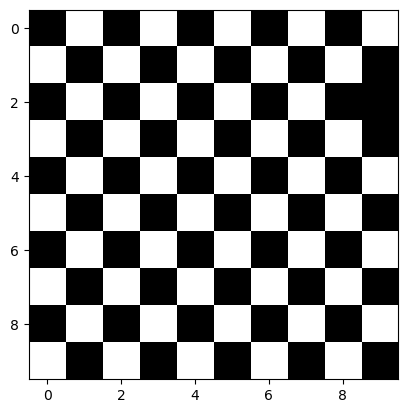

In [9]:
plt.imshow(checkers_img)

# Step 2: Building Rule Set from Images

Basically we want an algorithm that can walk over every single n x n region in our image and:
1. Find all unique blocks
2. Build a count of unique blocks that occur around it

So we need to be able to hash the block appearance, then under that have four object, up, left, right, down that each have a hash of block appearance that contains shape. We must also be able to turn this hash back into the actual shapes

In order to do this we can use a dict with a hash of a tuple of tuples.

In [10]:
test_tup = ((2,3),(3,4))
test_dic = {}
test_dic[test_tup] = 1
print(test_dic)
del test_dic
del test_tup

{((2, 3), (3, 4)): 1}


Now we need a way to convert an image block into a tuple

In [11]:
img_block = checkers_img[:2,:2]
img_block

array([[[  0,   0,   0, 255],
        [255, 255, 255, 255]],

       [[255, 255, 255, 255],
        [  0,   0,   0, 255]]], dtype=uint8)

In [12]:
def np_to_tuple(a):
    try:
        return tuple(np_to_tuple(i) for i in a)
    except TypeError:
        return a

In [13]:
def get_block(image, i, j, n):
    return np_to_tuple(image[i:i+n,j:j+n])

Okay now that we can convert into tuples we should have everything we need to build our data structure of rules

In [14]:
import collections

def build_rule_set(image, n):
    """
    Build a rule set from the image where each unique n x n block maps to a dictionary
    of Counters for each direction (up, down, left, right) indicating neighboring blocks.
    """
    rules = {}
    rows, cols, _ = tuple(image.shape)
    
    # Iterate through each valid starting position for an n x n block
    for i in range(rows - n + 1):
        for j in range(cols - n + 1):
            block = get_block(image, i, j, n)
            # Initialize the entry if not present
            if block not in rules:
                rules[block] = {
                    'up': collections.Counter(),
                    'down': collections.Counter(),
                    'left': collections.Counter(),
                    'right': collections.Counter()
                }
            
            # Update counters for each neighbor if they exist
            
            # Up: the block immediately above current block (if exists)
            if i > n - 1:
                neighbor = get_block(image, i-n, j, n)
                rules[block]['up'][neighbor] += 1

            # Down: the block immediately below current block (if exists)
            if i < rows - n:
                neighbor = get_block(image, i+n, j, n)
                rules[block]['down'][neighbor] += 1

            # Left: the block immediately to the left (if exists)
            if j > n - 1:
                neighbor = get_block(image, i, j-n, n)
                rules[block]['left'][neighbor] += 1

            # Right: the block immediately to the right (if exists)
            if j < cols - n:
                neighbor = get_block(image, i, j+n, n)
                rules[block]['right'][neighbor] += 1
                
    return rules

In [15]:
rules = build_rule_set(checkers_img, 2)

In [16]:
import numpy as np

In [17]:

def visualize_rule_set_pairs(rule_set):
    """
    For each rule (base block paired with one of its neighbors), display a row with two images:
      - Left: the base block.
      - Right: one neighbor block, with its direction and occurrence count in the title.
    Each pair is shown in a separate row.
    """
    for block, directions in rule_set.items():
        # Count the total neighbor entries for the block
        total_neighbors = sum(len(counter) for counter in directions.values())
        if total_neighbors == 0:
            continue  # Skip if there are no neighbors
        
        # Create a subplot grid with two columns and one row per neighbor.
        # Using squeeze=False to always get a 2D array.
        fig, axs = plt.subplots(total_neighbors, 2, figsize=(8, 4 * total_neighbors), squeeze=False)
        
        row_index = 0
        for direction, counter in directions.items():
            for neighbor, count in counter.items():
                # Left: base block image
                axs[row_index, 0].imshow(np.array(block), interpolation='nearest')
                axs[row_index, 0].set_title("Base Block")
                axs[row_index, 0].axis('off')
                
                # Right: neighbor block image
                axs[row_index, 1].imshow(np.array(neighbor), interpolation='nearest')
                axs[row_index, 1].set_title(f"{direction.capitalize()} neighbor (count: {count})")
                axs[row_index, 1].axis('off')
                
                row_index += 1
        
        plt.tight_layout()
        plt.show()

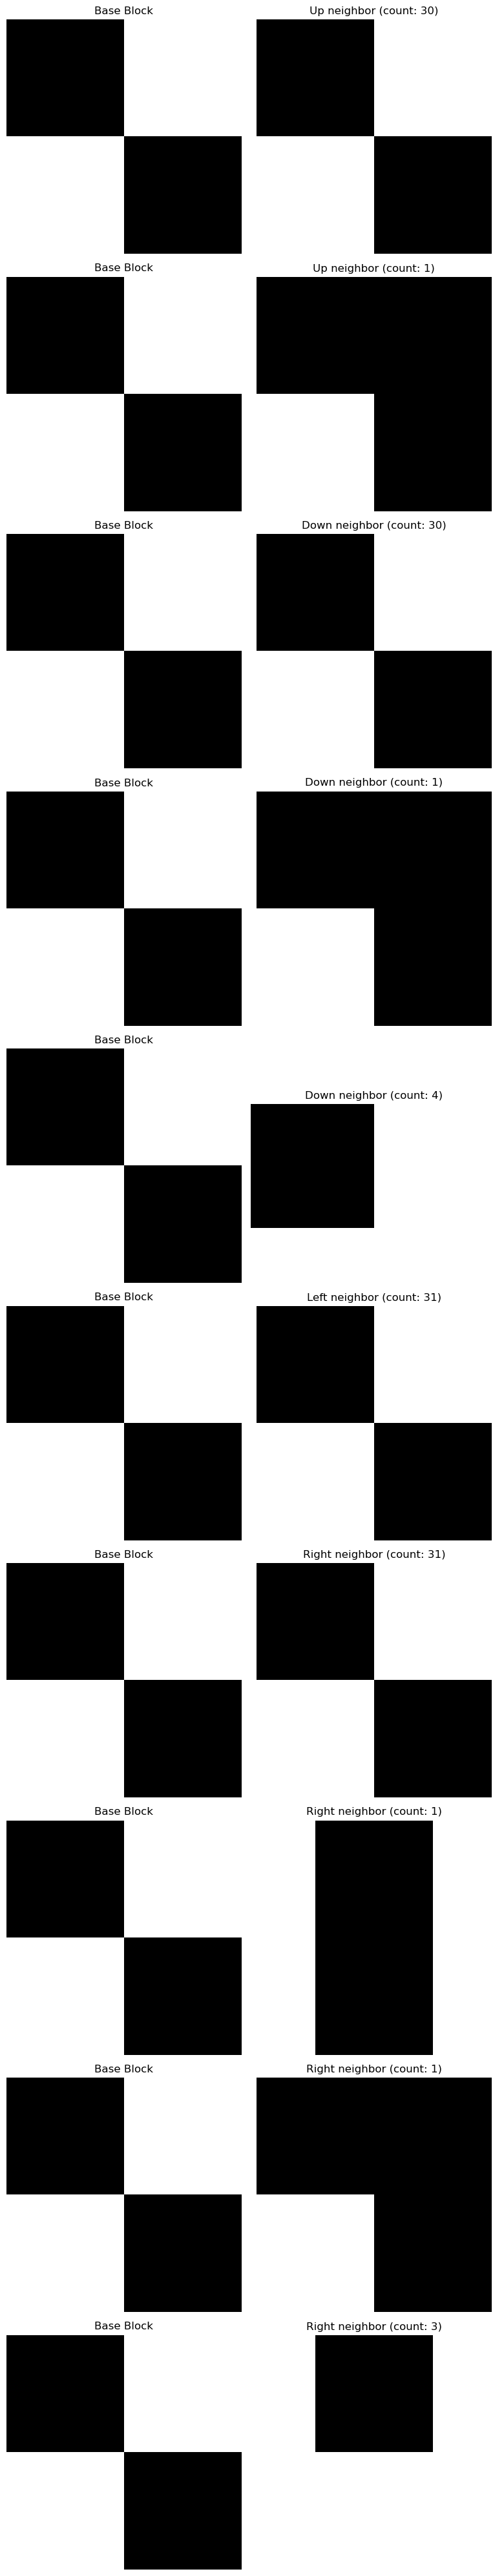

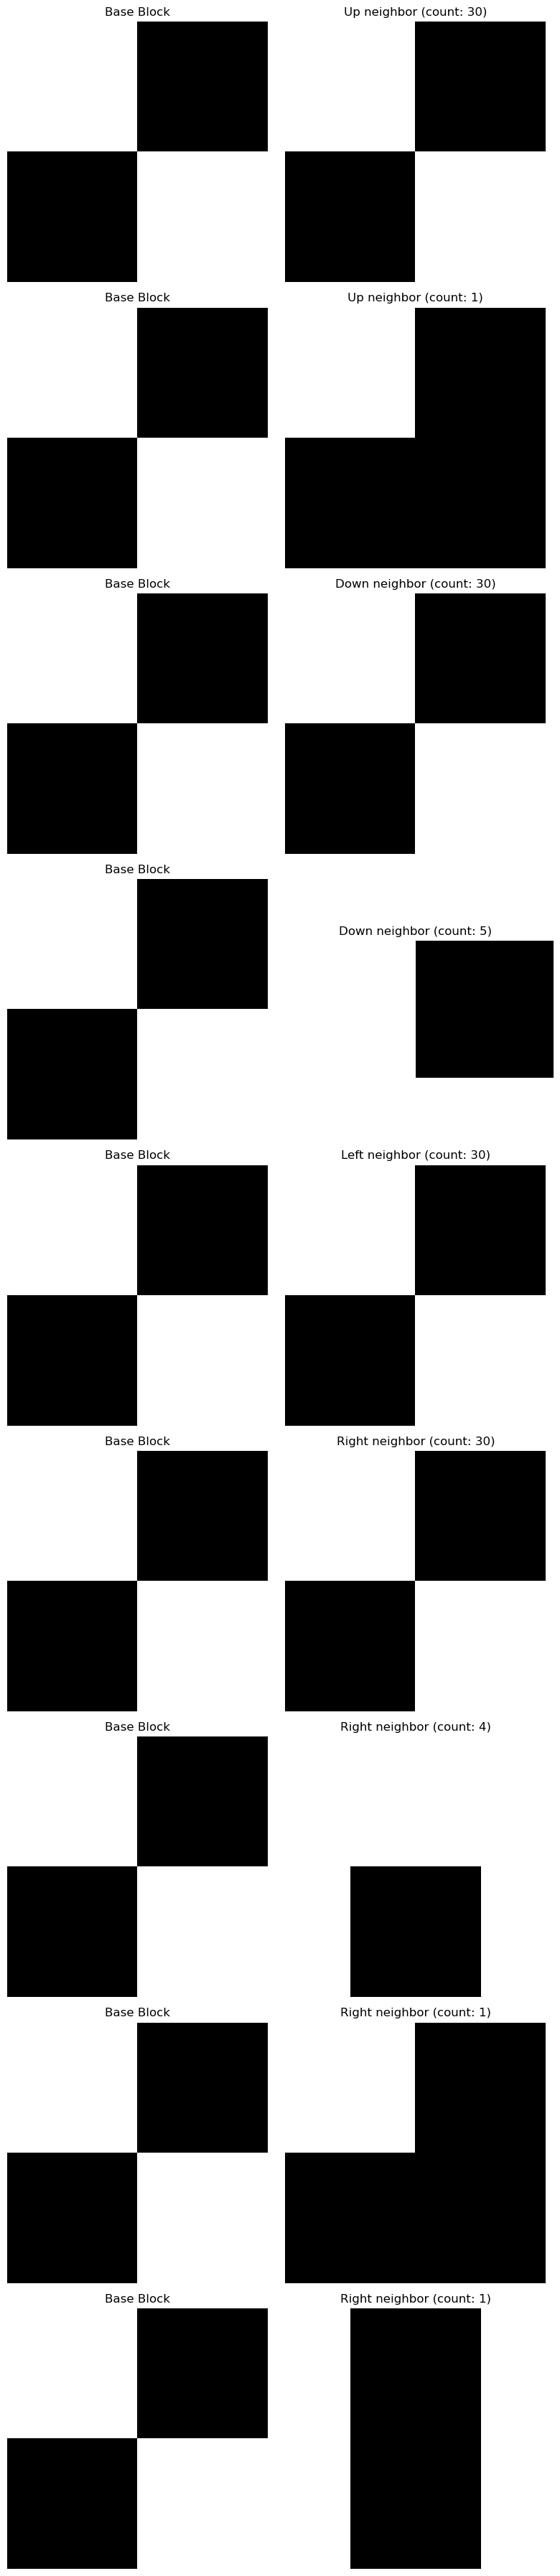

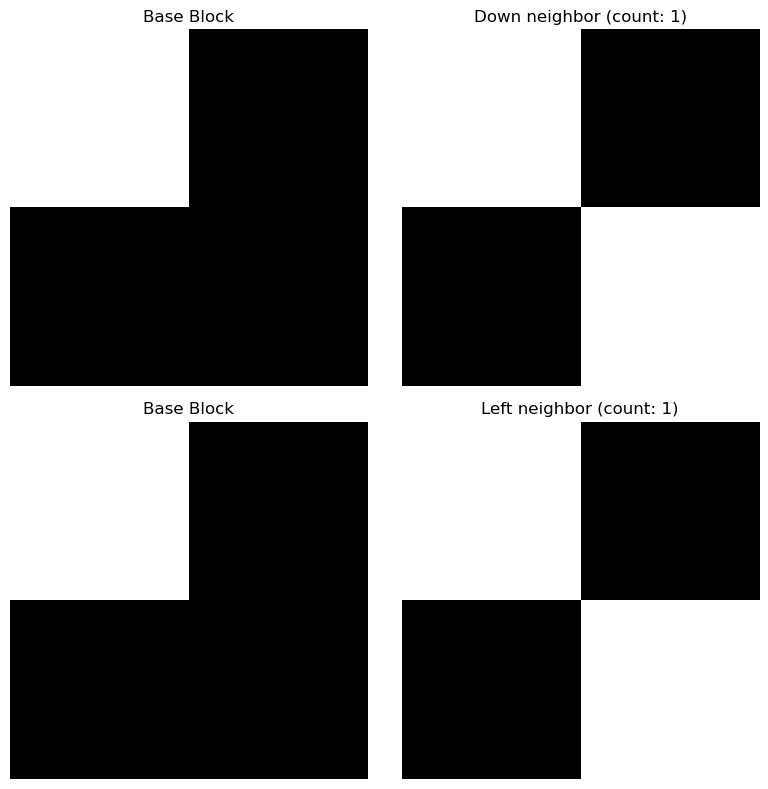

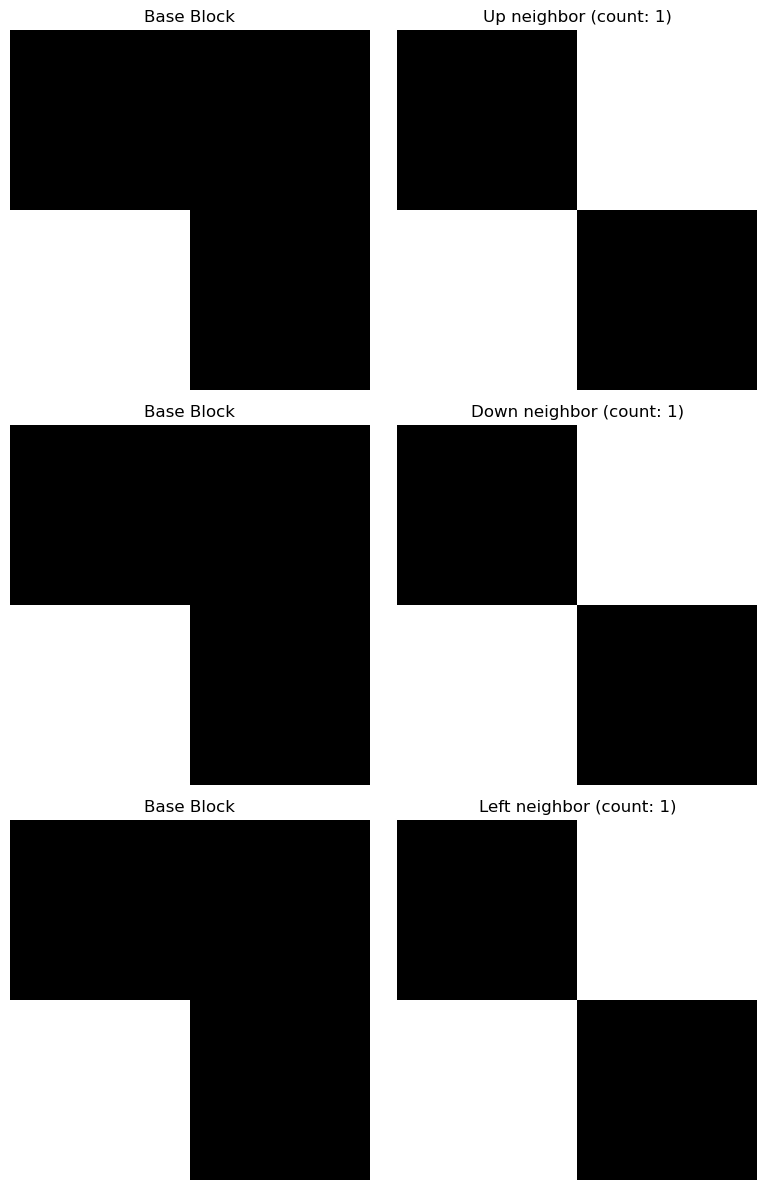

In [18]:
visualize_rule_set_pairs(rules)

# Step 3: Implimenting wave function collapse

In [167]:
from random import randrange

class WaveFunctionCollapse:
    w: int
    h: int
    img: np.ndarray
    sample_img: np.ndarray
    rules: dict
    bs: int
    def __init__(self, img_shape, img, block_size) -> None:
        w, h, _ = tuple(img_shape)
        self.w = w
        self.h = h
        self.img = np.zeros(img_shape)
        self.next_coords = set()
        self.gen_rules(img, block_size)
    def gen_rules(self, img, block_size):
        self.sample_img = img
        self.bs = block_size
        self.rules = build_rule_set(img, block_size)
    def display(self):
        plt.imshow(self.img)
    def get_random_coord(self):
        possible_coords = np.argwhere(self.img[:-1,:-1,3] == 0)
        coord = possible_coords[
            np.random.choice(possible_coords.shape[0])
        ]
        return (coord // self.bs) * self.bs
    def get_neighbors(self, coord):
        x,y = tuple(coord)
        rows, cols, _ = tuple(self.img.shape)
        neighbors = {
            'left': {
                'cords': [ x - self.bs, y],
                'inbounds': x > self.bs - 1,
            },
            'up': {
                'cords': [ x , y - self.bs],
                'inbounds': y > self.bs - 1,
            },
            'right': {
                'cords': [ x + self.bs, y],
                'inbounds': x < rows - self.bs,
            },
            'down': {
                'cords': [ x, y + self.bs],
                'inbounds': y < cols - self.bs,
            }
        }
        for key, value in neighbors.items():
            x, y = tuple(value['cords'])
            if value['inbounds']:
                neighbors[key]['filled'] = self.img[x,y,3] != 0
                neighbors[key]['value'] = self.img[x:x+self.bs,y:y+self.bs]
            else:
                neighbors[key]['filled'] = False
                neighbors[key]['value'] = None
        return neighbors
    def get_valid_fills(self, neighbors):
        # We need to be able to grab the rules pointing to the chunk in question from the neighbors
        dir_flipper = {
            'right': 'left',
            'left': 'right',
            'up': 'down',
            'down': 'up'
        }
        neighbor_counters = [
            self.rules[
                np_to_tuple(value)
            ][dir_flipper[key]]
            for key, value in neighbors.items()
        ]
        common_keys = set.intersection(*(set(c.keys()) for c in neighbor_counters))
        total = sum(neighbor_counters, collections.Counter())
        result = collections.Counter({k: total[k] for k in common_keys})
        return result 
    def step(self):
        coord = None
        if len(self.next_coords) == 0:
            coord = self.get_random_coord()
        else:
            index = np.random.randint(len(list(self.next_coords)))
            coord = list(self.next_coords)[index]
            self.next_coords.remove(coord)
        neighbors = self.get_neighbors(coord)
        for value in neighbors.values():
            if(value['inbounds'] and not value['filled']):
                self.next_coords.add(tuple(value['cords']))
        if all(inner.get('inbounds') and not inner.get('filled') for inner in neighbors.values()):
            valid_fills = list(self.rules.keys())
            choice = np.random.choice(len(valid_fills))
            fill = np.array(valid_fills[choice])
            x, y = tuple(coord)
            self.img[x:x+self.bs, y:y+self.bs] = fill
        else:
            valid_fills = self.get_valid_fills({
                key: value['value'] for key, value in neighbors.items() if value['inbounds'] and value['filled']
            })
            if len(valid_fills) == 0:
                raise Exception("No valid rules found in common")
            keys = list(valid_fills.keys())
            values = np.array(list(valid_fills.values()))

            probs = values / values.sum()

            sel_key_index = np.random.choice(range(len(keys)), p=probs)
            sel_key = keys[sel_key_index]
            fill = np.array(sel_key)

            x, y = tuple(coord)
            self.img[x:x+self.bs, y:y+self.bs] = fill

        # Get nieghbors
        # Build list of possible blocks
        # Find random block that is transperent

In [168]:
wfc = WaveFunctionCollapse([30,30,4], checkers_img, 2)

In [195]:
wfc.step()
wfc.display()

TypeError: unbound method set.intersection() needs an argument

# Step 3.2 Trying again

In [ ]:
class WaveFunctionCollapse:
    def __init__(self, img_width, img_height) -> None:
        self.w = img_width
        self.h = img_height
    def gen_ruleset(self, img, block_size):
        self.input_img = img
        self.bs = block_size
        # First we derive our rule set
        self.rules = build_rule_set(img, block_size)
        # Then we can use these rules to make a simple lookup table
        # First we need to make a lookup table for all possible blocks
        # Then we need to build a rule set for those possible blocks
    def step(self):
        # If we don't have a set of next step coords we choose a random coordinate
        # We append the random coordinates non-filled neighbors to the next steps object
        # We find a block to place at our coordinate

_IncompleteInputError: incomplete input (2610490831.py, line 1)

# Step 4: System to build video from steps